<a href="https://colab.research.google.com/github/devinlee114066522/HW3/blob/main/114066522_%E6%9D%8E%E6%A4%8D%E9%9B%8B_HW3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HW3: Hyperparameter Tuning

This notebook trains a baseline classifier on the chest X-ray dataset to distinguish **NORMAL** from **PNEUMONIA** images.

It is organized as follows: import libraries → define training / validation / test functions → prepare data → build model → set hyperparameters and train → plot learning curves → evaluate on the test set.

Use this notebook as a starting point. You are free to modify any part of it (hyperparameters, model architecture, data augmentation, etc.) for your experiments, and summarize your findings in the analysis report.

# Import Library

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import random
import time
import torch
import torch.nn as nn
import torch.optim as optims

from sklearn.metrics import accuracy_score
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.transforms.functional import InterpolationMode

This cell sets up the computing device and checks whether a GPU is available. Training on a GPU is much faster than on a CPU.

In [2]:
device = torch.device('cuda')
gpu_count = torch.cuda.device_count()

print("Using", gpu_count, "GPUs")
print("CUDA is available:", torch.cuda.is_available())

Using 1 GPUs
CUDA is available: True


This cell defines the three functions used throughout the homework:

- **`train_one_epoch`**: trains the model for one epoch on the training set (forward pass → loss → backpropagation → weight update) and returns the average loss and accuracy.
- **`val_one_epoch`**: evaluates the model on the validation set without updating weights, and saves the checkpoint with the best validation accuracy.
- **`evaluate`**: loads the saved best model and reports the final loss and accuracy on the test set.

In [3]:
# train loop
def train_one_epoch(model, device, criterion, optimizer, train_data_loader):
    epoch_loss = []
    epoch_acc = []
    start_time = time.time()

    model.train()

    for batch_idx, (images, labels) in enumerate (train_data_loader):
        images = images.to(device)
        labels = labels.to(device).float()
        optimizer.zero_grad()
        preds = model(images)
        loss = criterion(preds, labels.unsqueeze(1))

        # Calculating Loss
        epoch_loss.append(loss.item())

        # Calculating Metrics
        predicts = (preds > 0.5).float()
        predicts = predicts.view(-1)
        predicts = predicts.detach().cpu().numpy()
        labels = labels.detach().cpu().numpy()
        acc = accuracy_score(labels, predicts)

        epoch_acc.append(acc)

        # Backpropagation
        loss.backward()
        optimizer.step()

    # Overall Epoch Results
    end_time = time.time()
    total_time = end_time - start_time

    epoch_loss = np.mean(epoch_loss)
    epoch_acc = np.mean(epoch_acc) * 100

    return epoch_loss, epoch_acc, total_time

# validation loop
def val_one_epoch(model, device, criterion, val_data_loader, best_acc, save):
    epoch_loss = []
    epoch_acc = []
    start_time = time.time()

    model.eval()

    with torch.no_grad():
        for images, labels in val_data_loader:
            images = images.to(device)
            labels = labels.to(device).float()
            preds = model(images)

            # Calculating Loss
            loss = criterion(preds, labels.unsqueeze(1))
            epoch_loss.append(loss.item())

            # Calculating Metrics
            predicts = (preds > 0.5).float()
            predicts = predicts.view(-1)
            predicts = predicts.detach().cpu().numpy()
            labels = labels.detach().cpu().numpy()
            acc = accuracy_score(labels, predicts)
            epoch_acc.append(acc)

    # Overall Epoch Results
    end_time = time.time()
    total_time = end_time - start_time

    epoch_loss = np.mean(epoch_loss)
    epoch_acc = np.mean(epoch_acc) * 100

    # Saving best model
    if epoch_acc > best_acc:
        best_acc = epoch_acc
        torch.save(model.state_dict(), f"{save}.pth")

    return epoch_loss, epoch_acc, total_time, best_acc

# evaluate loop (test loop)
def evaluate(model, device, model_path, test_loader):
    try:
        model.load_state_dict(torch.load(model_path))
        print("Model weights loaded successfully.")
    except Exception as e:
        print("Warning: Failed to load model weights. Using randomly initialized weights instead.")
        print(e)

    model.to(device)
    model.eval()

    test_loss = []
    test_acc = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device).float()

            # Forward pass
            preds = model(images)

            # Calculating loss
            loss = criterion(preds, labels.unsqueeze(1))
            test_loss.append(loss.item())

            # Calculating accuracy
            predicts = (preds > 0.5).float()
            predicts = predicts.view(-1)
            predicts = predicts.detach().cpu().numpy()
            labels = labels.detach().cpu().numpy()
            acc = accuracy_score(labels, predicts)
            test_acc.append(acc)

    # Overall test results
    avg_test_loss = np.mean(test_loss)
    avg_test_acc = np.mean(test_acc) * 100

    print(f"Test Accuracy: {avg_test_acc:.2f}%")
    print(f"Test Loss: {avg_test_loss:.4f}")

    return avg_test_loss, avg_test_acc

# Data Preparation

Mount Google Drive so the notebook can read the dataset stored in your Drive.

In [4]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [ ]:
import os

check_path = '/content/drive/MyDrive/DL_HW3_ver2/train/train/PNEUMONIA'
print(f"正在檢查路徑: {check_path}")

if not os.path.exists(check_path):
    print("❌ 錯誤：找不到這個資料夾！請確認你是否已經執行了 drive.mount('/content/drive')，或者你的資料夾名稱是否有打錯。")
else:
    files = os.listdir(check_path)
    print(f"✅ 資料夾存在！裡面共有 {len(files)} 個檔案。")
    if len(files) > 0:
        print("前 5 個檔案名稱如下：")
        for f in files[:5]:
            print(f" - {f}")
    else:
        print("⚠️ 警告：資料夾是空的！代表你的圖片根本沒有上傳到 Google 雲端硬碟，請重新上傳。")

正在檢查路徑: /content/drive/MyDrive/DL_HW3_ver2/train/train/PNEUMONIA
✅ 資料夾存在！裡面共有 1000 個檔案。
前 5 個檔案名稱如下：
 - person74_bacteria_362.jpeg
 - person98_virus_182.jpeg
 - person77_bacteria_377.jpeg
 - person76_bacteria_372.jpeg
 - person94_virus_176.jpeg


In [ ]:
import os
import shutil
from sklearn.model_selection import train_test_split

base_dir = '/content/drive/MyDrive/DL_HW3_ver2'
new_base_dir = '/content/drive/MyDrive/DL_HW3_ver2_split'
classes = ['NORMAL', 'PNEUMONIA']
all_files = {'NORMAL': [], 'PNEUMONIA': []}

# 1. 遞迴搜尋 base_dir 底下的所有圖片，不用管原本在哪一層
for root, dirs, files in os.walk(base_dir):
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
            # 根據資料夾名稱判斷類別 (統一轉大寫避免大小寫錯誤)
            if 'NORMAL' in root.upper():
                all_files['NORMAL'].append(os.path.join(root, f))
            elif 'PNEUMONIA' in root.upper():
                all_files['PNEUMONIA'].append(os.path.join(root, f))

# 顯示蒐集結果
for cls in classes:
    print(f"{cls} 類別共找到 {len(all_files[cls])} 張圖片")

if sum(len(v) for v in all_files.values()) == 0:
    print("錯誤：找不到任何圖片，請確認 base_dir 路徑是否完全正確！")
else:
    # 2. 建立新資料夾結構 (保留雙層結構 split/split/cls)
    for split in ['train', 'val', 'test']:
        for cls in classes:
            os.makedirs(os.path.join(new_base_dir, split, split, cls), exist_ok=True)

    # 3. 分割與複製
    for cls in classes:
        files = all_files[cls]

        # 若圖片太少無法分割
        if len(files) < 3:
            print(f"警告：{cls} 圖片太少無法分割，全數放入 train")
            for f in files:
                shutil.copy(f, os.path.join(new_base_dir, 'train', 'train', cls))
            continue

        # 使用 95% / 2.5% / 2.5%
        train_files, temp_files = train_test_split(files, train_size=0.95, random_state=42)
        val_files, test_files = train_test_split(temp_files, test_size=0.5, random_state=42)

        def copy_files(file_list, split_name):
            for f in file_list:
                shutil.copy(f, os.path.join(new_base_dir, split_name, split_name, cls))

        copy_files(train_files, 'train')
        copy_files(val_files, 'val')
        copy_files(test_files, 'test')
        print(f"{cls} 分割複製完成: train={len(train_files)}, val={len(val_files)}, test={len(test_files)}")

    print("所有資料複製完畢！請記得將 ImageFolder 的路徑改為新資料夾。")

NORMAL 類別共找到 1242 張圖片
PNEUMONIA 類別共找到 1398 張圖片
NORMAL 分割複製完成: train=1179, val=31, test=32
PNEUMONIA 分割複製完成: train=1328, val=35, test=35
所有資料複製完畢！請記得將 ImageFolder 的路徑改為新資料夾。


This cell prepares the data:

1. **Paths**: set the folders for the train / validation / test sets (change them to where you stored the dataset).
2. **Transforms**: resize every image to 256×256, convert it to a single grayscale channel, and turn it into a tensor. `train_transform` is applied only to the training set, so this is where data augmentation can be added.
3. **Datasets & DataLoaders**: `ImageFolder` labels each image by its folder name (NORMAL / PNEUMONIA), and `DataLoader` splits the data into batches.

In [5]:
# define folder path for each set
train_path = '/content/drive/MyDrive/DL_HW3_ver2_split/train/train'
test_path = '/content/drive/MyDrive/DL_HW3_ver2_split/test/test'
val_path = '/content/drive/MyDrive/DL_HW3_ver2_split/val/val'

# define transformation
train_transform = transforms.Compose([
    transforms.Resize((256, 256), interpolation=InterpolationMode.BICUBIC),
    transforms.Grayscale(num_output_channels=1),
    transforms.RandomRotation(degrees=10), # 正負 10 度內的隨機旋轉
    transforms.ColorJitter(brightness=0.2),

    transforms.ToTensor(),
])

common_transform = transforms.Compose([
    transforms.Resize((256, 256), interpolation=InterpolationMode.BICUBIC),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
])

# create datasets
train_dataset = datasets.ImageFolder(train_path, transform=train_transform)
test_dataset = datasets.ImageFolder(test_path, transform=common_transform)
val_dataset = datasets.ImageFolder(val_path, transform=common_transform)

# create dataloaders
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

# Model

This cell builds the baseline model: a fully connected network (MLP) that flattens each image into a vector and passes it through three hidden layers (Linear → BatchNorm → ReLU → Dropout). The final Sigmoid outputs the probability of pneumonia for binary classification.

In [6]:
model = nn.Sequential(
    nn.Flatten(),

    nn.Linear(256 * 256 * 1, 512),
    nn.BatchNorm1d(512),
    nn.ReLU(),
    nn.Dropout(0.1),

    nn.Linear(512, 256),
    nn.BatchNorm1d(256),
    nn.ReLU(),
    nn.Dropout(0.1),

    nn.Linear(256, 128),
    nn.BatchNorm1d(128),
    nn.ReLU(),
    nn.Dropout(0.1),

    nn.Linear(128, 64),
    nn.BatchNorm1d(64),
    nn.ReLU(),
    nn.Dropout(0.1),

    nn.Linear(64, 1),
    nn.Sigmoid()
)

model.to(device)
print(model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=65536, out_features=512, bias=True)
  (2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (3): ReLU()
  (4): Dropout(p=0.1, inplace=False)
  (5): Linear(in_features=512, out_features=256, bias=True)
  (6): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (7): ReLU()
  (8): Dropout(p=0.1, inplace=False)
  (9): Linear(in_features=256, out_features=128, bias=True)
  (10): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (11): ReLU()
  (12): Dropout(p=0.1, inplace=False)
  (13): Linear(in_features=128, out_features=64, bias=True)
  (14): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (15): ReLU()
  (16): Dropout(p=0.1, inplace=False)
  (17): Linear(in_features=64, out_features=1, bias=True)
  (18): Sigmoid()
)


# Loop

This cell sets the training hyperparameters: learning rate, weight decay, learning rate scheduler, number of epochs, optimizer, and loss function (binary cross-entropy). `save` is the file name for the best model checkpoint.

In [9]:
# hyperparameter
lr = 0.001
weight_decay = 0.001
optimizer = optims.Adam(model.parameters(), lr=lr, weight_decay = weight_decay)

lr_scheduler = optims.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
epochs = 30

criterion = nn.BCELoss()

# save checkpoint
save = 'model'

This cell runs the training loop. Each epoch trains on the training set, evaluates on the validation set, records the loss and accuracy, prints the results, and lets the learning rate scheduler adjust the learning rate based on the validation accuracy.

In [10]:
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

best_acc = 0.0
output_list = []

for epoch in range(epochs):
    train_loss, train_acc, train_time = train_one_epoch(model, device, criterion, optimizer, train_loader)
    val_loss, val_acc, val_time, best_acc = val_one_epoch(model, device, criterion, val_loader, best_acc, save)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    total_time = train_time + val_time
    output_str = f"Epoch {epoch+1}/{epochs} - loss: {train_loss:.4f} - train_acc: {train_acc:.2f}% - val_loss: {val_loss:.4f} - val_acc: {val_acc:.2f}% - time: {total_time:.2f}s"
    output_list.append(output_str)
    print(output_str)
    lr_scheduler.step()

Epoch 1/30 - loss: 0.2101 - train_acc: 91.75% - val_loss: 0.8419 - val_acc: 66.67% - time: 86.51s
Epoch 2/30 - loss: 0.1805 - train_acc: 92.93% - val_loss: 0.6461 - val_acc: 69.70% - time: 85.74s
Epoch 3/30 - loss: 0.1985 - train_acc: 92.41% - val_loss: 1.2496 - val_acc: 62.12% - time: 84.97s
Epoch 4/30 - loss: 0.1684 - train_acc: 93.49% - val_loss: 0.3253 - val_acc: 86.36% - time: 85.31s
Epoch 5/30 - loss: 0.1659 - train_acc: 93.46% - val_loss: 0.8385 - val_acc: 54.55% - time: 85.70s
Epoch 6/30 - loss: 0.1592 - train_acc: 94.02% - val_loss: 0.6872 - val_acc: 60.61% - time: 85.72s
Epoch 7/30 - loss: 0.1754 - train_acc: 93.08% - val_loss: 1.3968 - val_acc: 53.03% - time: 85.28s
Epoch 8/30 - loss: 0.1661 - train_acc: 93.80% - val_loss: 0.6601 - val_acc: 66.67% - time: 85.79s
Epoch 9/30 - loss: 0.1508 - train_acc: 93.32% - val_loss: 0.3826 - val_acc: 81.82% - time: 85.34s
Epoch 10/30 - loss: 0.1640 - train_acc: 94.11% - val_loss: 1.2794 - val_acc: 63.64% - time: 85.45s
Epoch 11/30 - loss:

# Graph

This cell plots the training and validation loss and accuracy curves over epochs. Use them to check whether the model converges and whether it is overfitting or underfitting.

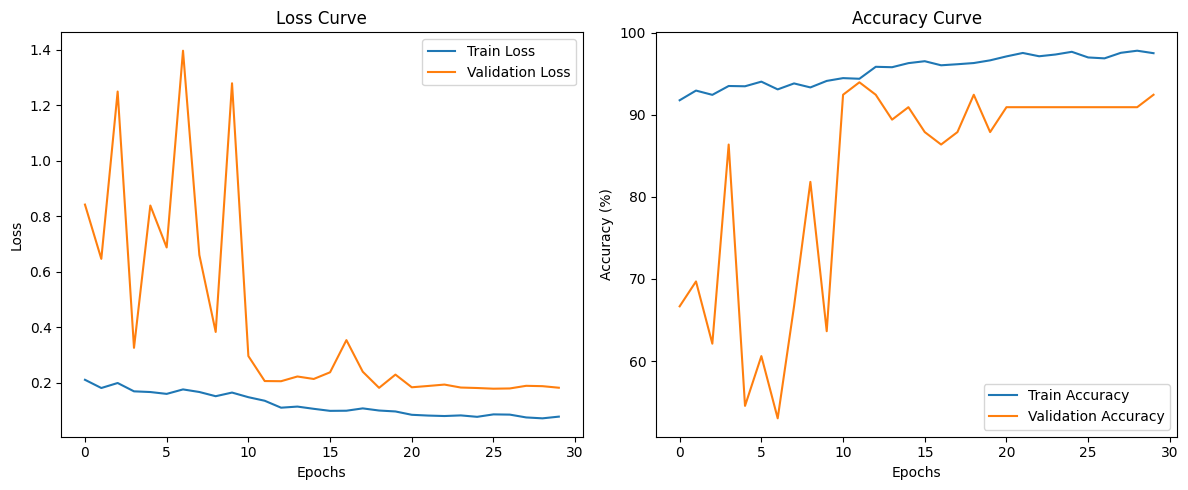

In [11]:
plt.figure(figsize=(12, 5))

# loss graph
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# accuracy graph
plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label='Train Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')
plt.title('Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()

# show
plt.tight_layout()
plt.show()

# Evaluate

This cell loads the best checkpoint saved during training and evaluates it on the test set, which the model has never seen, to report its final performance.

In [12]:
model_path = 'model.pth'
avg_test_loss, avg_test_acc = evaluate(model, device, model_path, test_loader)

Model weights loaded successfully.
Test Accuracy: 95.52%
Test Loss: 0.0802
